# data load

In [61]:
import osmnx as ox
import networkx as nx
import r5py

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import h3
import h3pandas
import pyrosm

pd.set_option("display.max_columns", None)

In [319]:
import json

filename = "mi_poliono.json"
with open(filename) as f:
    geojson = json.load(f)

print(json.dumps(geojson, indent=2))

{
  "type": "FeatureCollection",
  "features": [
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              -73.06346529166855,
              -36.84340287657342
            ],
            [
              -73.02486725809113,
              -36.84340287657342
            ],
            [
              -73.02486725809113,
              -36.81050088149721
            ],
            [
              -73.06346529166855,
              -36.81050088149721
            ],
            [
              -73.06346529166855,
              -36.84340287657342
            ]
          ]
        ]
      }
    }
  ]
}


In [316]:
poligono_gdf = gpd.GeoDataFrame.from_features(geojson["features"])
poligono_gdf

,geometry
0,"POLYGON ((-73.06347 -36.8434, -73.02487 -36.84..."


In [317]:
poligono_gdf.to_file("poligono.shp")

c:\Users\secua\Documents\nicolas\accessity\env\Lib\site-packages\pyogrio\geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


## Cargar área de estudio

Opciones:

1. Con nombre del lugar\
(según nominatim https://nominatim.openstreetmap.org/ui/reverse.html?lat=-36.82381882597611&lon=-73.05084228515626&zoom=10)

```python
    place_name = "Concepción, Chile"
```

Área cargada con éxito: "Concepcion, Provincia de Concepción, Biobio Region, Chile"


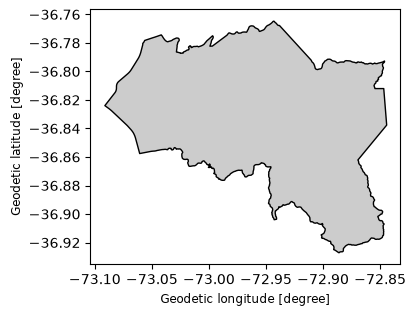

In [139]:
# selección de lugar (según nominatim)
place_name = "Concepción, Chile"

try:
    area_gdf = ox.geocode_to_gdf(place_name)
    area = area_gdf.geometry.union_all()
    area_gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")
    print(f"Área cargada con éxito: \"{area_gdf.iloc[0].display_name}\"")
except:
    print("ERROR: Nombre no reconocido")

In [136]:
area_gdf.to_parquet("conce.parquet")

2. Con `.shp` (SHAPEFILE) o `.parquet` (PARQUET) colocado en la misma carpeta donde está este archivo `accessibility_calculation.ipynb`

```python
    place_shp = "custom_polygon.shp"
    place_parquet = "custom_polygon.parquet"
```

IMPORTANTE: Sólo es necesario uno, ya sea SHAPEFILE o PARQUET, dejar el otro con string vacío `""`

Polígono "poligono.shp" cargado con éxito


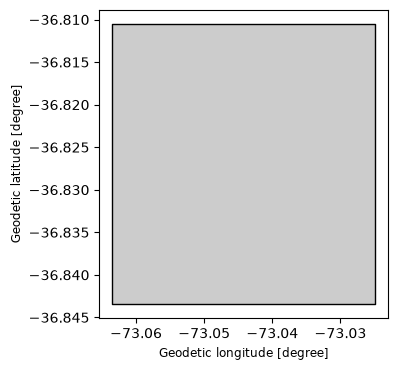

In [ ]:
# selección de archivo a cargar
place_shp = "poligono.shp"
place_parquet = ""

if place_shp:
    try:
        area_gdf = gpd.read_file(place_shp)
        area_gdf = area_gdf.set_crs()
        area_gdf = area_gdf.to_crs(4326)
        area = area_gdf.geometry.union_all()
        area_gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")
        print(f"Polígono \"{place_shp}\" cargado con éxito")
    except:
        print(f"ERROR: No se pudo abrir el archivo {place_shp}")
elif place_parquet:
    try:
        area_gdf = gpd.read_parquet(place_parquet)
        area = area_gdf.geometry.union_all()
        area_gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")
        print(f"Polígono \"{place_parquet}\" cargado con éxito")
    except:
        print(f"ERROR: No se pudo abrir el archivo {place_parquet}")
else:
    print(f"ERROR: Se debe especificar un archivo .shp o .parquet")

In [322]:
# archivos OSM, GTFS
fp = "concepcion.osm.pbf"
gtfs = "gtfs_14102026.zip"
network_type="drive"

# amenity tags
tags = {
    "amenity": True,
    # add other keys like "shop": True if you want
    # also pick specific ones with "shop": ["supermarket", "books"]
}

# # point spacing in meters
# point_spacing = 50

# hexagon resolution (uber H3)
h3_resolution = 10

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

In [312]:
# area_gdf = ox.geocode_to_gdf(place_name)
# area = area_gdf.geometry.iloc[0]
# area

In [323]:
osm = pyrosm.OSM(fp, bounding_box=area)
osm

In [311]:
# # load blocks from census
# # i will use this after to discard hexagons without any people

# blocks_gdf = gpd.read_parquet("blocks/Cartografia_censo2024_Pais_Manzanas.parquet")
# blocks_gdf = blocks_gdf[blocks_gdf.COMUNA == "CONCEPCIÓN"]
# blocks_gdf = blocks_gdf.rename(columns={"SHAPE": "geometry"})
# blocks_gdf = gpd.GeoDataFrame(blocks_gdf, geometry="geometry", crs=4326)
# blocks_gdf

In [328]:
# load blocks from census keeping the intersecting ones
# i will use this after to discard hexagons without any people

blocks_gdf = gpd.read_parquet("blocks/Cartografia_censo2024_Pais_Manzanas.parquet")
match_indices = blocks_gdf.sindex.query([area], predicate="intersects")
blocks_gdf = blocks_gdf.iloc[match_indices[1]]

# blocks_gdf = blocks_gdf[blocks_gdf.n_per > 0]

blocks_gdf = blocks_gdf.rename(columns={"SHAPE": "geometry"})
blocks_gdf = gpd.GeoDataFrame(blocks_gdf, geometry="geometry", crs=4326)

print(len(blocks_gdf))
blocks_gdf.head()

693


,OBJECTID,CUT,COD_REGION,REGION,COD_PROVINCIA,PROVINCIA,COMUNA,AREA_C,MANZENT,DISTRITO,COD_DISTRITO,COD_LOCALIDAD,COD_ZONA,LOCALIDAD,COD_ENTIDAD,COD_MANZANA,ENTIDAD,TIPO_MZ,COD_CATEGORIA,CATEGORIA,MZ_BASE_CENSO,ID_ENTIDAD,ID_LOCALIDAD,ID_DISTRITO,ID_ZONA,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,prom_edad,n_inmigrantes,n_nacionalidad,n_pueblos_orig,n_afrodescendencia,n_lengua_indigena,n_religion,n_dificultad_ver,n_dificultad_oir,n_dificultad_mover,n_dificultad_cogni,n_dificultad_cuidado,n_dificultad_comunic,n_discapacidad,n_estcivcon_casado,n_estcivcon_conviviente,n_estcivcon_conv_civil,n_estcivcon_anul_sep_div,n_estcivcon_viudo,n_estcivcon_soltero,prom_escolaridad18,n_asistencia_parv,n_asistencia_basica,n_asistencia_media,n_asistencia_superior,n_cine_nunca_curso_primera_infancia,n_cine_primaria,n_cine_secundaria,n_cine_terciaria_maestria_doctorado,n_cine_especial_diferencial,n_analfabet,n_ocupado,n_desocupado,n_fuera_fuerza_trabajo,n_cise_rec_independientes,n_cise_rec_dependientes,n_cise_rec_trabajador_no_remunerado,n_ciuo_1,n_ciuo_2,n_ciuo_3,n_ciuo_4,n_ciuo_5,n_ciuo_6,n_ciuo_7,n_ciuo_8,n_ciuo_9,n_ciuo_0,n_caenes_A,n_caenes_B,n_caenes_C,n_caenes_D,n_caenes_E,n_caenes_F,n_caenes_G,n_caenes_H,n_caenes_I,n_caenes_J,n_caenes_K,n_caenes_L,n_caenes_M,n_caenes_N,n_caenes_O,n_caenes_P,n_caenes_Q,n_caenes_R,n_caenes_S,n_caenes_T,n_caenes_U,n_transporte_auto,n_transporte_publico,n_transporte_camina,n_transporte_bicicleta,n_transporte_motocicleta,n_transporte_cab_lan_bote,n_transporte_otros,n_hog,prom_per_hog,n_hog_unipersonales,n_hog_60,n_hog_menores,n_jefatura_mujer,n_tenencia_propia_pagada,n_tenencia_propia_pagandose,n_tenencia_arrendada_contrato,n_tenencia_arrendada_sin_contrato,n_tenencia_cedida_trabajo,n_tenencia_cedida_familiar,n_tenencia_otro,n_comb_cocina_gas,n_comb_cocina_parafina,n_comb_cocina_lena,n_comb_cocina_pellet,n_comb_cocina_carbon,n_comb_cocina_electricidad,n_comb_cocina_solar,n_comb_cocina_no_utiliza,n_comb_calefaccion_gas,n_comb_calefaccion_parafina,n_comb_calefaccion_lena,n_comb_calefaccion_pellet,n_comb_calefaccion_carbon,n_comb_calefaccion_electricidad,n_comb_calefaccion_otra,n_comb_calefaccion_no_utiliza,n_serv_tel_movil,n_serv_compu,n_serv_tablet,n_serv_internet_fija,n_serv_internet_movil,n_serv_internet_satelital,n_internet,n_vp,n_vp_ocupada,n_vp_desocupada,n_tipo_viv_casa,n_tipo_viv_depto,n_tipo_viv_indigena,n_tipo_viv_pieza,n_tipo_viv_mediagua,n_tipo_viv_movil,n_tipo_viv_otro,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_viv_hacinadas,n_viv_irrecuperables,n_hog_allegados,n_nucleos_hacinados_allegados,n_viv_no_ampliables,n_deficit_cuantitativo,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_mat_techo_tejas,n_mat_techo_hormigon,n_mat_techo_zinc,n_mat_techo_fibrocemento,n_mat_techo_fonolita,n_mat_techo_paja,n_mat_techo_precarios,n_mat_techo_sin_cubierta,n_mat_piso_radier_con_revestimiento,n_mat_piso_radier_sin_revestimiento,n_mat_piso_baldosa_cemento,n_mat_piso_capa_cemento,n_mat_piso_tierra,n_fuente_agua_publica,n_fuente_agua_pozo,n_fuente_agua_camion,n_fuente_agua_rio,n_distrib_agua_llave,n_distrib_agua_llave_fuera,n_distrib_agua_acarreo,n_serv_hig_alc_dentro,n_serv_hig_alc_fuera,n_serv_hig_fosa,n_serv_hig_pozo,n_serv_hig_acequia_canal,n_serv_hig_cajon_otro,n_serv_hig_bano_quimico,n_serv_hig_bano_seco,n_serv_hig_no_tiene,n_fuente_elect_publica,n_fuente_elect_diesel,n_fuente_elect_solar,n_fuente_elect_eolica,n_fuente_elect_otro,n_fuente_elect_no_tiene,n_basura_servicios,n_basura_entierra,n_basura_eriazo,n_basura_rio,n_basura_otro,SHAPE_Length,SHAPE_Area,geometry
21844,21845,8101,8,BIOBÍO,81,CONCEPCIÓN,CONCEPCIÓN,URBANO,8.101321e+12,LO PEQUÉN,32,7,2,GRAN CONCEPCIÓN,1,25,CONCEPCIÓN,URBANO,1,Ciudad,0,8.101007e+11,81011007.0,810132.0,810132002.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

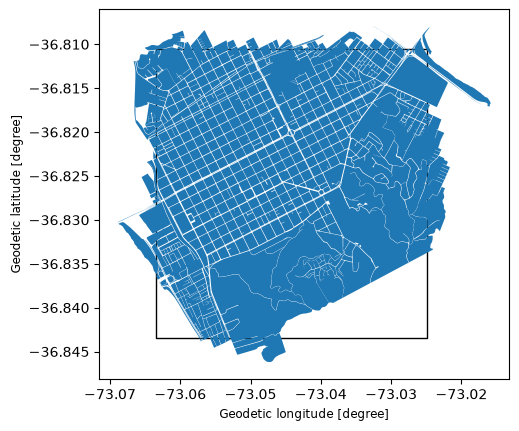

In [326]:
ax = area_gdf.plot(color="none")
blocks_gdf.plot(ax=ax)

In [10]:
# # generate the point grid

# # project to UTM to improve the location of points
# bounds = blocks_gdf.to_crs(32718).total_bounds

# # sample coordinates along x and y axis with numpy arange
# points_x = np.arange(bounds[0], bounds[2], point_spacing)
# points_y = np.arange(bounds[1], bounds[3], point_spacing)

# # create points with the coordinates paired as tuples
# points = shapely.points([(x, y) for x in points_x for y in points_y])

# # create the points_gdf from the points
# points_gdf = gpd.GeoDataFrame(geometry=points, crs=32718)
# points_gdf = points_gdf.to_crs(4326)

# # intersect with the city blocks with actual people living there (n_per > 0)
# # match_indices = points_gdf.sindex.query(area, predicate="intersects")
# match_indices = points_gdf.sindex.query(blocks_gdf.geometry, predicate="intersects")
# points_gdf = points_gdf.iloc[match_indices[1]]
# points_gdf = points_gdf.reset_index()

# # create x, y columns for standarization purposes only
# points_gdf["x"] = points_gdf.geometry.x
# points_gdf["y"] = points_gdf.geometry.y
# points_gdf = points_gdf[["x", "y", "geometry"]]
# points_gdf = points_gdf.reset_index(names="id")

# print(len(points_gdf))
# points_gdf.head()

c:\Users\secua\Documents\nicolas\accessity\env\Lib\site-packages\h3pandas\h3pandas.py:750: UserWarning: 119 rows did not generate a H3 cell.Consider using a finer resolution.
  warnings.warn(


1073


,cell,geometry
0,8ab2d868a197fff,"POLYGON ((-73.0155 -36.81701, -73.015 -36.8165..."
1,8ab2d868a487fff,"POLYGON ((-73.02246 -36.82147, -73.02197 -36.8..."
2,8ab2d868a497fff,"POLYGON ((-73.02371 -36.82172, -73.02321 -36.8..."
3,8ab2d868a49ffff,"POLYGON ((-73.02271 -36.82254, -73.02221 -36.8..."
4,8ab2d868a4a7fff,"POLYGON ((-73.02222 -36.8204, -73.02172 -36.81..."


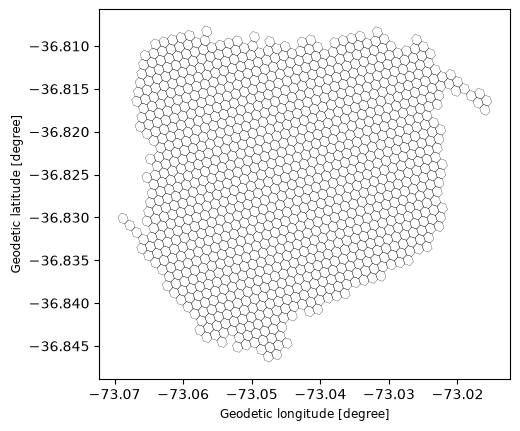

In [329]:
# # hexagons_gdf = gpd.read_parquet(f"data/{place_string}/hexagons_{h3_resolution}.parquet")

# # get all the h3 hexagons from all the points generated
# # (which already are inside blocks with people)

# points_gdf["cell"] = points_gdf.apply(lambda p: h3.latlng_to_cell(p.y, p.x, h3_resolution), 1)
# cells = points_gdf.cell
# cells = cells.drop_duplicates()

# hexagons = [h3.cell_to_boundary(cell) for cell in cells]

# # invert coordinates as h3.cell_to_boundary returns points with
# # their coordinates flipped for some reason (?)
# hexagons = [[(c[1], c[0]) for c in g] for g in hexagons]

# # create the polygons
# polygons = shapely.polygons(hexagons)

# # create the hexagons_gdf with those polygons
# hexagons_gdf = gpd.GeoDataFrame({"cell": cells}, geometry=polygons, crs=4326)

hexagons_gdf = blocks_gdf.h3.polyfill_resample(h3_resolution + 1).h3.h3_to_parent_aggregate(h3_resolution)
hexagons_gdf = hexagons_gdf.reset_index(names="cell")
hexagons_gdf = hexagons_gdf[["cell", "geometry"]]

print(len(hexagons_gdf))
hexagons_gdf.plot(color="none", linewidth=0.2)
hexagons_gdf.head()

In [330]:
# get points of interest from osm as they will be the destination

pois_gdf = osm.get_pois(custom_filter=tags)

pois_gdf = pois_gdf.to_crs(32718)
pois_gdf.geometry = pois_gdf.geometry.centroid
pois_gdf = pois_gdf.to_crs(4326)

pois_gdf = pois_gdf[~pois_gdf["amenity"].isna()]
pois_gdf = pois_gdf[pois_gdf['amenity'] != 'bench']

pois_gdf.lon = pois_gdf.geometry.x
pois_gdf.lat = pois_gdf.geometry.y
pois_gdf = pois_gdf.rename(columns={"lon": "x", "lat": "y"})

pois_gdf = pois_gdf[["id", "x", "y", "amenity", "geometry"]]

In [ ]:
# load buildings

buildings_gdf = gpd.read_parquet(f"data/{place_string}/buildings.parquet")
buildings_gdf = buildings_gdf[buildings_gdf.confidence >= 0.7]
buildings_gdf.head()

In [287]:
# match_indices = hexagons_gdf.sindex.query(buildings_gdf.geometry, predicate="intersects")
# matching_hexagons_gdf = hexagons_gdf.iloc[match_indices[1]]
# matching_hexagons_gdf = matching_hexagons_gdf.drop_duplicates("cell")
# # matching_hexagons_gdf = matching_hexagons_gdf.drop(columns="id")
# matching_hexagons_gdf = matching_hexagons_gdf.reset_index(drop=True)
# matching_hexagons_gdf = matching_hexagons_gdf.reset_index(names="id")
# matching_hexagons_gdf.head()

In [288]:
# match_indices = points_gdf.sindex.query(matching_hexagons_gdf.geometry, predicate="intersects")
# matching_points_gdf = points_gdf.iloc[match_indices[1]]
# matching_points_gdf = matching_points_gdf.reset_index(drop=True)
# # matching_points_gdf["cell"] = matching_hexagons_gdf.iloc[match_indices[0]].cell.reset_index(drop=True)
# matching_points_gdf = matching_points_gdf.drop(columns="id")
# matching_points_gdf = matching_points_gdf.reset_index(names="id")
# matching_points_gdf.head()

In [161]:
# blocks_gdf["area"] = blocks_gdf.to_crs(32718).geometry.area
# blocks_gdf["area"]

In [162]:
# overlaid_hexagons_gdf = matching_hexagons_gdf.overlay(blocks_gdf[["MANZENT", "n_per", "area", "SHAPE"]].to_crs(4326))
# overlaid_hexagons_gdf = overlaid_hexagons_gdf.rename(columns={"area": "block_area"})
# overlaid_hexagons_gdf.MANZENT = overlaid_hexagons_gdf.MANZENT.astype(int)
# overlaid_hexagons_gdf["area"] = overlaid_hexagons_gdf.to_crs(32718).geometry.area
# overlaid_hexagons_gdf

In [163]:
# ax = hexagons_gdf.plot(figsize=(30,30), alpha=0.2)
# matching_hexagons_gdf.plot(ax=ax, color="red", alpha=0.5)
# # points_gdf.plot(ax=ax)
# matching_points_gdf.plot(ax=ax, markersize=0.1, color="black")

# accessibility

C:\Users\secua\AppData\Local\Temp\ipykernel_32904\1943068682.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  origins_gdf.geometry = origins_gdf.geometry.centroid


1073


,id,cell,geometry
0,0,8ab2d868a197fff,POINT (-73.01575 -36.81638)
1,1,8ab2d868a487fff,POINT (-73.02271 -36.82084)
2,2,8ab2d868a497fff,POINT (-73.02396 -36.82109)
3,3,8ab2d868a49ffff,POINT (-73.02296 -36.82191)
4,4,8ab2d868a4a7fff,POINT (-73.02246 -36.81977)


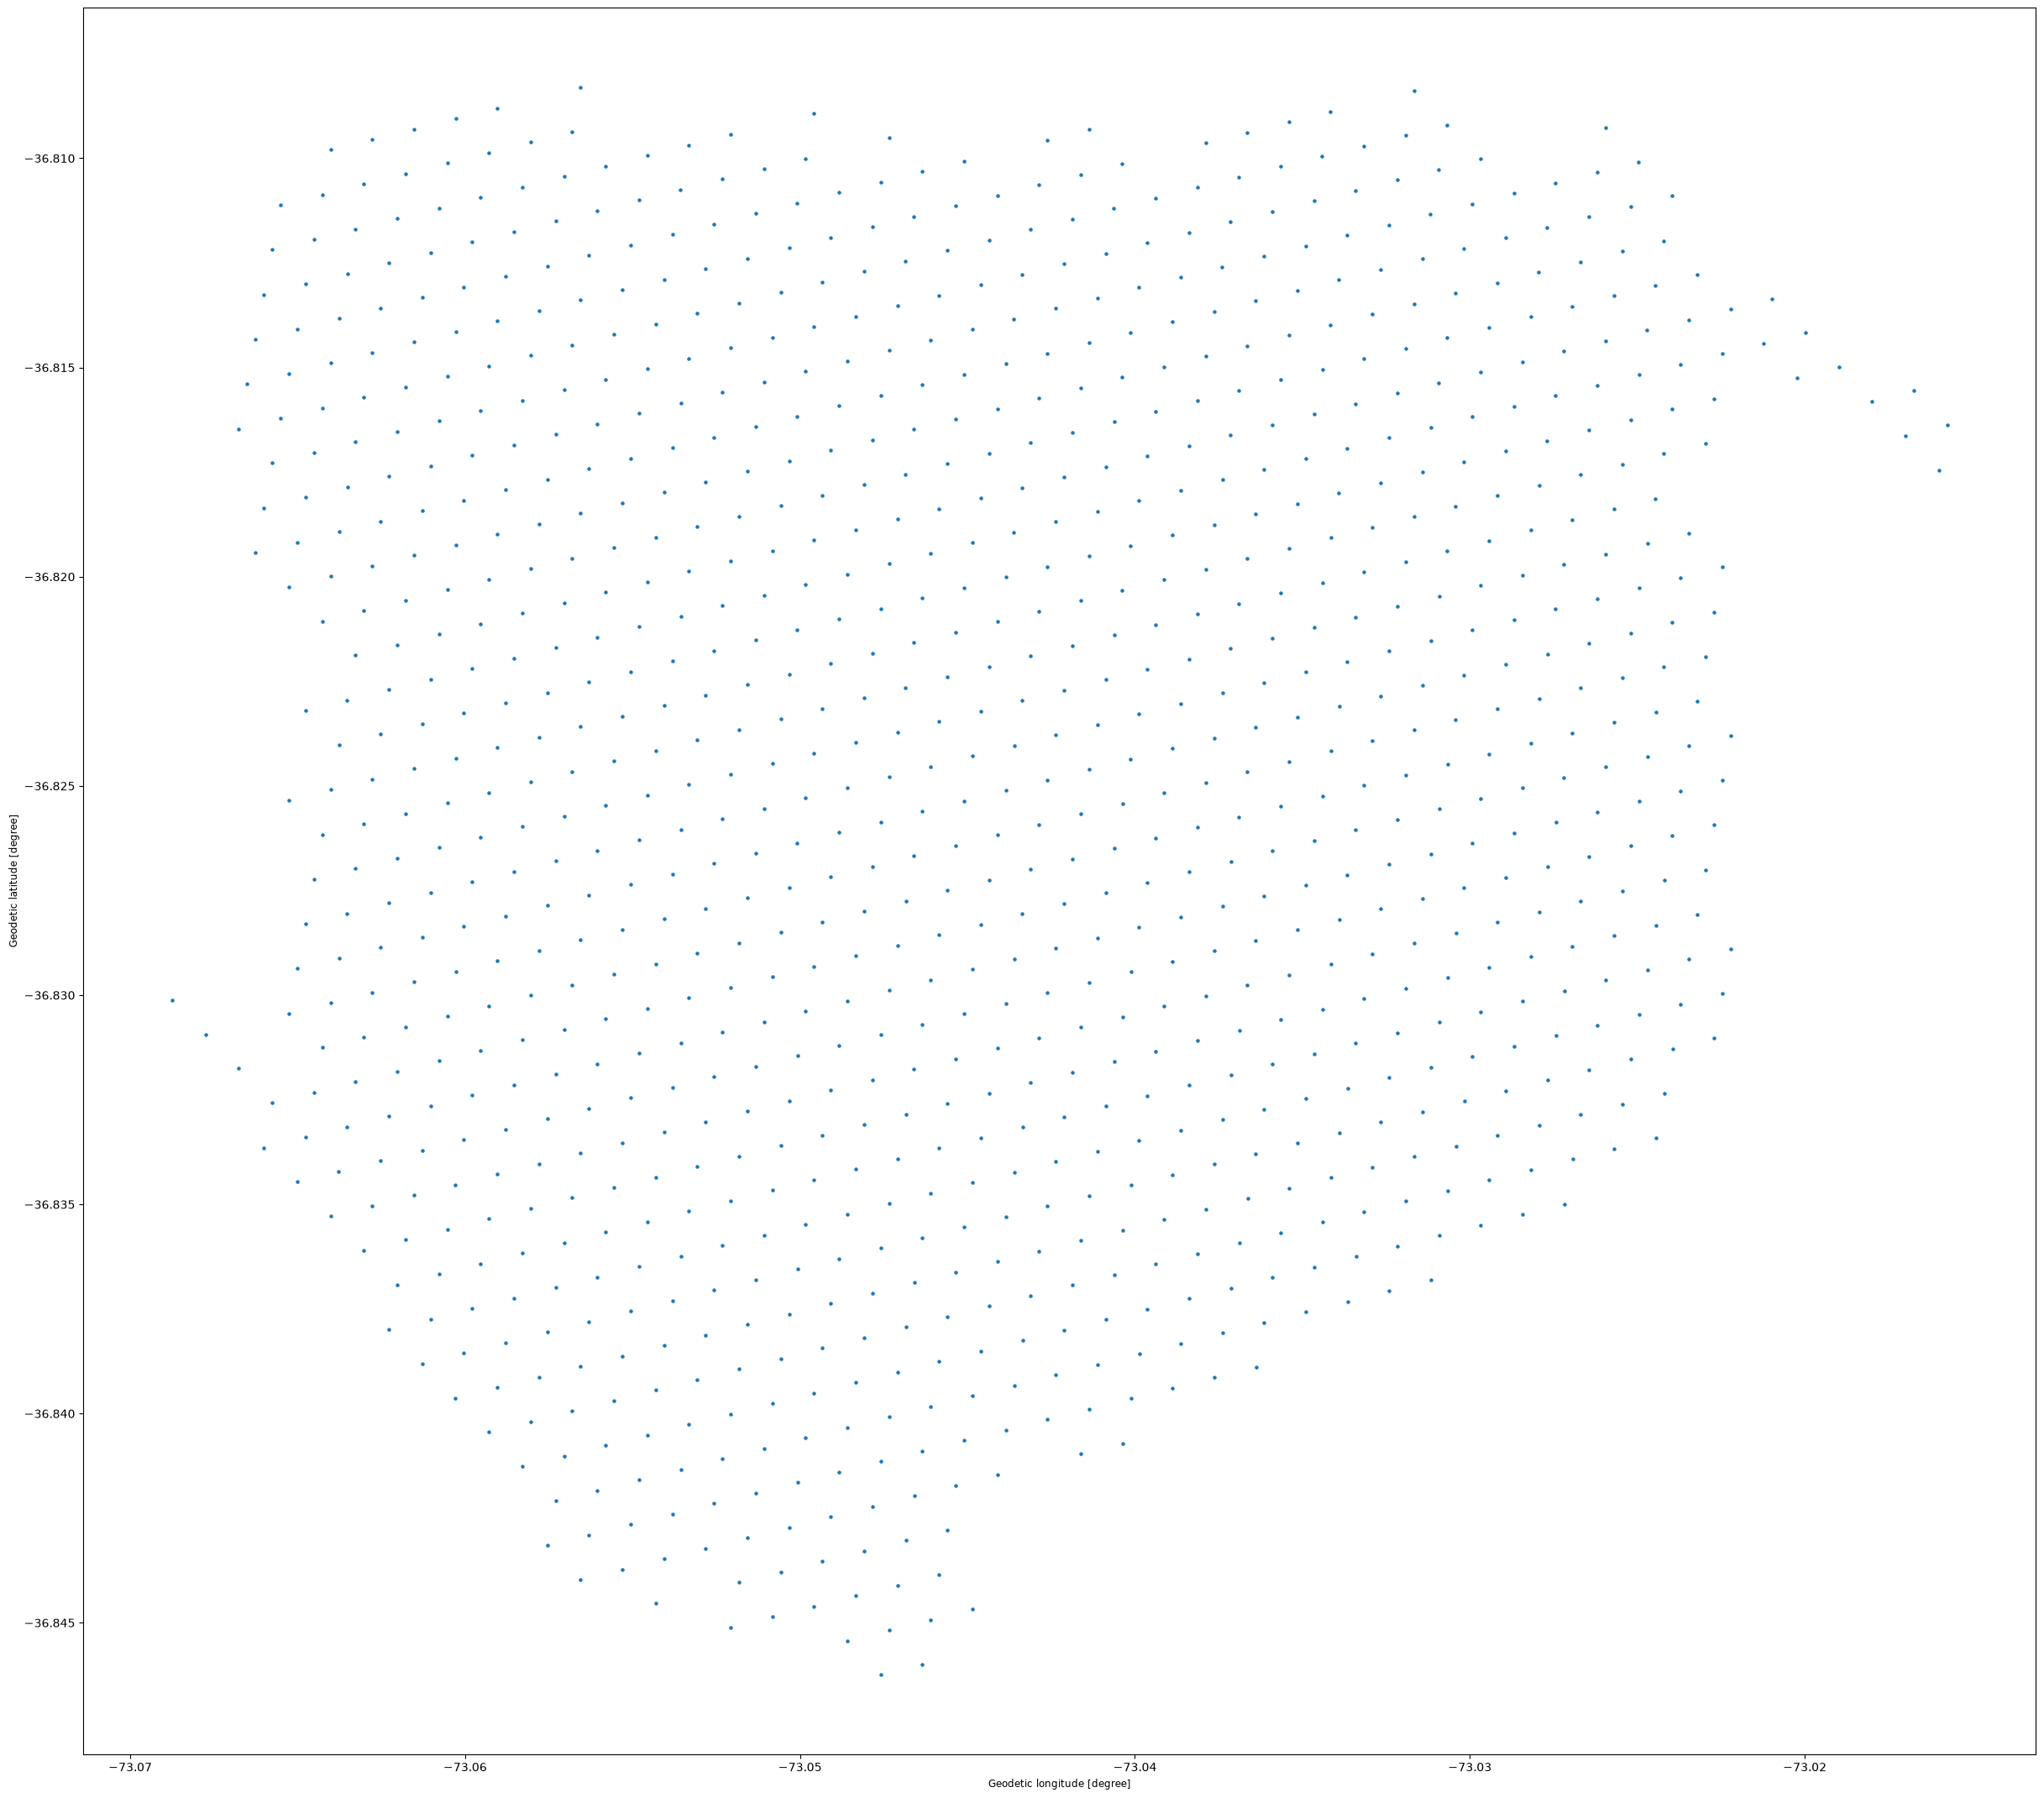

In [332]:
origins_gdf = hexagons_gdf.copy()
origins_gdf.geometry = origins_gdf.geometry.centroid
origins_gdf = origins_gdf.reset_index(names="id")
origins_gdf.plot(figsize=(30,30), markersize=5)
print(len(origins_gdf))
origins_gdf.head()

In [333]:
destinations_gdf = pois_gdf
destinations_gdf = destinations_gdf.drop(columns="id", errors="ignore")
destinations_gdf = destinations_gdf.reset_index(drop=True)
destinations_gdf = destinations_gdf.reset_index(names="id")
print(len(destinations_gdf))
destinations_gdf.head()

1091


,id,x,y,amenity,geometry
0,0,-73.049019,-36.825828,pharmacy,POINT (-73.04902 -36.82583)
1,1,-73.049807,-36.826167,pharmacy,POINT (-73.04981 -36.82617)
2,2,-73.049703,-36.828868,pharmacy,POINT (-73.0497 -36.82887)
3,3,-73.049033,-36.826076,pharmacy,POINT (-73.04903 -36.82608)
4,4,-73.036547,-36.833695,bar,POINT (-73.03655 -36.83369)


In [ ]:
transport_network = r5py.TransportNetwork(
    osm_pbf=fp,
    gtfs=["gtfs_14102026.zip"]
)
transport_network

In [299]:
# import pyrosm

# # pyrosm acepta tu polígono (4326) directamente para filtrar el PBF de forma eficiente
# osm = pyrosm.OSM(fp, bounding_box=area)

# # extraer la red del tipo network_type junto con sus nodos
# nodes, edges = osm.get_network(network_type="all", nodes=True)

# edges = edges[edges.highway.isin(["motorway", "trunk", "primary", "secondary", "tertiary", "residential", "unclassified", "living_street", "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link", "service"])]

# # cortar usando el spatial index de geopandas
# match_indices = edges.sindex.query(area, predicate="intersects")
# edges = edges.iloc[match_indices]

# # filtrar únicamente los nodos que pertenecen a las aristas recortadas
# node_ids = set(edges['u']).union(set(edges['v']))
# nodes = nodes[nodes['id'].isin(node_ids)]

# # nodes.lon = nodes.geometry.x
# # nodes.lat = nodes.geometry.y

# # renombrar lon, lat a x, y
# nodes = nodes.rename(columns={'lon': 'x', 'lat': 'y'})

# # convertirlo a un grafo G de networkx
# G = osm.to_graph(nodes, edges, graph_type="networkx", simplify=True)

# print(f"done\n{len(G.nodes):,} nodes\n{len(G.edges):,} edges")

In [ ]:
# osm = pyrosm.OSM(fp, bounding_box=area)

# # extraer la red del tipo network_type junto con sus nodos
# nodes, edges = osm.get_network(network_type=network_type, nodes=True)

# # cortar usando el spatial index de geopandas
# match_indices = edges.sindex.query(area, predicate="intersects")
# edges = edges.iloc[match_indices]

# # filtrar únicamente los nodos que pertenecen a las aristas recortadas
# node_ids = set(edges['u']).union(set(edges['v']))
# nodes = nodes[nodes['id'].isin(node_ids)]

# # nodes.lon = nodes.geometry.x
# # nodes.lat = nodes.geometry.y

# # renombrar lon, lat a x, y
# nodes = nodes.rename(columns={'lon': 'x', 'lat': 'y'})

# # convertirlo a un grafo G de networkx
# # # 1. Download or load the street network directly into an OSMnx graph
# # # You can customize network_type, or build it from a custom polygon/place name
# # G = ox.graph_from_place("Concepción, Chile", network_type="drive", simplify=True)
# G = osm.to_graph(nodes, edges, graph_type="networkx", simplify=True)
# G

In [301]:
# import osmnx as ox
# import networkx as nx
# import pandas as pd

# # 2. Automatically add travel time attributes to every edge (in seconds)
# # OSMnx calculates this based on speed limits and edge lengths
# G = ox.add_edge_speeds(G)
# G = ox.add_edge_travel_times(G)

# # --- YOUR CUSTOM CONTROL GOES HERE ---
# # Example: If you want to modify a specific edge or node weight directly:
# # u_node, v_node, key = list(G.edges(keys=True))[0]
# # G[u_node][v_node][key]['travel_time'] = 5.0 # Force a specific custom weight
# # -------------------------------------

# # 3. Find the nearest graph nodes for your origins and destinations GeoDataFrames
# origins_gdf['node'] = ox.distance.nearest_nodes(G, origins_gdf.geometry.x, origins_gdf.geometry.y)
# destinations_gdf['node'] = ox.distance.nearest_nodes(G, destinations_gdf.geometry.x, destinations_gdf.geometry.y)

# # 4. Compute the Travel Time Matrix using NetworkX Dijkstra shortest paths
# matrix_rows = []

# print("Computing travel time matrix...")
# for orig_idx, row in origins_gdf.iterrows():
#     orig_node = row['node']
    
#     # Calculate shortest path travel times from this origin to ALL nodes in the graph
#     # weight='travel_time' ensures it uses seconds computed by OSMnx
#     path_lengths = nx.single_source_dijkstra_path_length(G, source=orig_node, weight='travel_time')
    
#     for dest_idx, dest_row in destinations_gdf.iterrows():
#         dest_node = dest_row['node']
        
#         # Get travel time in seconds, default to infinity if unreachable
#         time_seconds = path_lengths.get(dest_node, float('inf'))
#         time_minutes = time_seconds / 60.0
        
#         matrix_rows.append({
#             'origin_id': orig_idx,
#             'destination_id': dest_idx,
#             'travel_time_min': time_minutes
#         })

# # 5. Convert results into a clean Pandas DataFrame matrix
# travel_time_matrix = pd.DataFrame(matrix_rows)
# travel_time_matrix.head()

In [ ]:
import datetime

def get_travel_time_matrix(transport_mode="DRIVE"):
    modes = transport_mode if isinstance(transport_mode, list) else transport_mode
    return  r5py.TravelTimeMatrix(
        transport_network=transport_network,
        origins=origins_gdf,
        destinations=destinations_gdf,
        transport_modes=[r5py.TransportMode.],
        # snap_to_network=True,
        # departure=datetime.datetime(2019, 5, 13, 14, 0, 0),
    )

print("computin WALK travel times")
travel_time_matrix_walk = get_travel_time_matrix("WALK")

print("computin CAR travel times")
travel_time_matrix_car = get_travel_time_matrix("CAR")

print("computin BUS travel times")
travel_time_matrix_bus = get_travel_time_matrix("BUS")

travel_time_matrix_bus

computin WALK travel times
computin CAR travel times
computin BUS travel times


,from_id,to_id,travel_time
0,0,0,0.0
1,0,1,40.0
2,0,2,42.0
3,0,3,40.0
4,0,4,53.0
...,...,...,...
1170638,1072,1086,35.0
1170639,1072,1087,35.0
1170640,1072,1088,36.0
1170641,1072,1089,28.0


In [353]:
travel_time_matrices = {
    "walk": travel_time_matrix_walk,
    "car": travel_time_matrix_car,
    "bus": travel_time_matrix_bus,
}

In [339]:
# travel_time_matrix.pivot(index="from_id", columns="to_id", values="travel_time")

In [354]:
matrix_gdfs = {}

for key, travel_time_matrix in travel_time_matrices.items():
    matrix_gdfs[key] = travel_time_matrix.copy()
    matrix_gdfs[key] = matrix_gdfs[key].merge(origins_gdf, "outer", left_on="from_id", right_on="id")
    matrix_gdfs[key] = matrix_gdfs[key].drop(columns="id")
    matrix_gdfs[key] = matrix_gdfs[key].merge(destinations_gdf[["id", "amenity"]], "outer", left_on="to_id", right_on="id")
    matrix_gdfs[key] = matrix_gdfs[key].drop(columns="id")
    matrix_gdfs[key] = matrix_gdfs[key][["from_id", "to_id", "cell", "amenity", "travel_time", "geometry"]]
    matrix_gdfs[key] = gpd.GeoDataFrame(matrix_gdfs[key], geometry="geometry", crs=4326)

matrix_gdfs[key]

,from_id,to_id,cell,amenity,travel_time,geometry
0,0,0,8ab2d868a197fff,pharmacy,0.0,POINT (-73.01575 -36.81638)
1,1,0,8ab2d868a487fff,pharmacy,26.0,POINT (-73.02271 -36.82084)
2,2,0,8ab2d868a497fff,pharmacy,28.0,POINT (-73.02396 -36.82109)
3,3,0,8ab2d868a49ffff,pharmacy,28.0,POINT (-73.02296 -36.82191)
4,4,0,8ab2d868a4a7fff,pharmacy,24.0,POINT (-73.02246 -36.81977)
...,...,...,...,...,...,...
1170638,1068,1090,8ab2d869e367fff,parking,24.0,POINT (-73.06576 -36.81219)
1170639,1069,1090,8ab2d869e36ffff,parking,19.0,POINT (-73.06476 -36.81301)
1170640,1070,1090,8ab2d869ea4ffff,parking,21.0,POINT (-73.06277 -36.80955)
1170641,1071,1090,8ab2d869ea5ffff,parking,22.0,POINT (-73.06402 -36.8098)


In [355]:
filter_amenity = "hospital"

hex_matrix_gdfs = {}
for key, matrix_gdf in matrix_gdfs.items():
    hex_matrix_gdfs[key] = matrix_gdf.copy()
    hex_matrix_gdfs[key] = hex_matrix_gdfs[key][hex_matrix_gdfs[key].amenity == filter_amenity].groupby("cell").agg({
        "amenity": "first",
        "travel_time": "min" # AGREACIÓN DEL MÍNIMO (APLICAR FUNCIÓN ACUMULATIVA)
        })
    geoms = hexagons_gdf.set_index("cell").geometry.loc[hex_matrix_gdfs[key].index]
    hex_matrix_gdfs[key] = gpd.GeoDataFrame(hex_matrix_gdfs[key], geometry=geoms, crs=4326)


hex_matrix_gdfs[key]

,amenity,travel_time,geometry
cell,,,
8ab2d868a197fff,hospital,31.0,"POLYGON ((-73.0155 -36.81701, -73.015 -36.8165..."
8ab2d868a487fff,hospital,18.0,"POLYGON ((-73.02246 -36.82147, -73.02197 -36.8..."
8ab2d868a497fff,hospital,21.0,"POLYGON ((-73.02371 -36.82172, -73.02321 -36.8..."
8ab2d868a49ffff,hospital,20.0,"POLYGON ((-73.02271 -36.82254, -73.02221 -36.8..."
8ab2d868a4a7fff,hospital,15.0,"POLYGON ((-73.02222 -36.8204, -73.02172 -36.81..."
...,...,...,...
8ab2d869e367fff,hospital,35.0,"POLYGON ((-73.06551 -36.81282, -73.06501 -36.8..."
8ab2d869e36ffff,hospital,31.0,"POLYGON ((-73.06451 -36.81364, -73.06402 -36.8..."
8ab2d869ea4ffff,hospital,33.0,"POLYGON ((-73.06252 -36.81018, -73.06202 -36.8..."


In [344]:
# load network to draw edges
osm = pyrosm.OSM(fp, bounding_box=area)
nodes, edges = osm.get_network(network_type=network_type, nodes=True)

# spatial index clip
match_indices = edges.sindex.query(area, predicate="intersects")
edges = edges.iloc[match_indices]

# filter nodes referenced by edges
node_ids = set(edges['u']).union(set(edges['v']))
nodes = nodes[nodes['id'].isin(node_ids)]

# build networkx graph
nodes = nodes.rename(columns={'lon': 'x', 'lat': 'y'})
G = osm.to_graph(nodes, edges, graph_type="networkx", simplify=True)

# extract simplified nodes and edges gdfs
nodes, edges = ox.graph_to_gdfs(G)

(-36.846873246818056, -36.80766703804427)

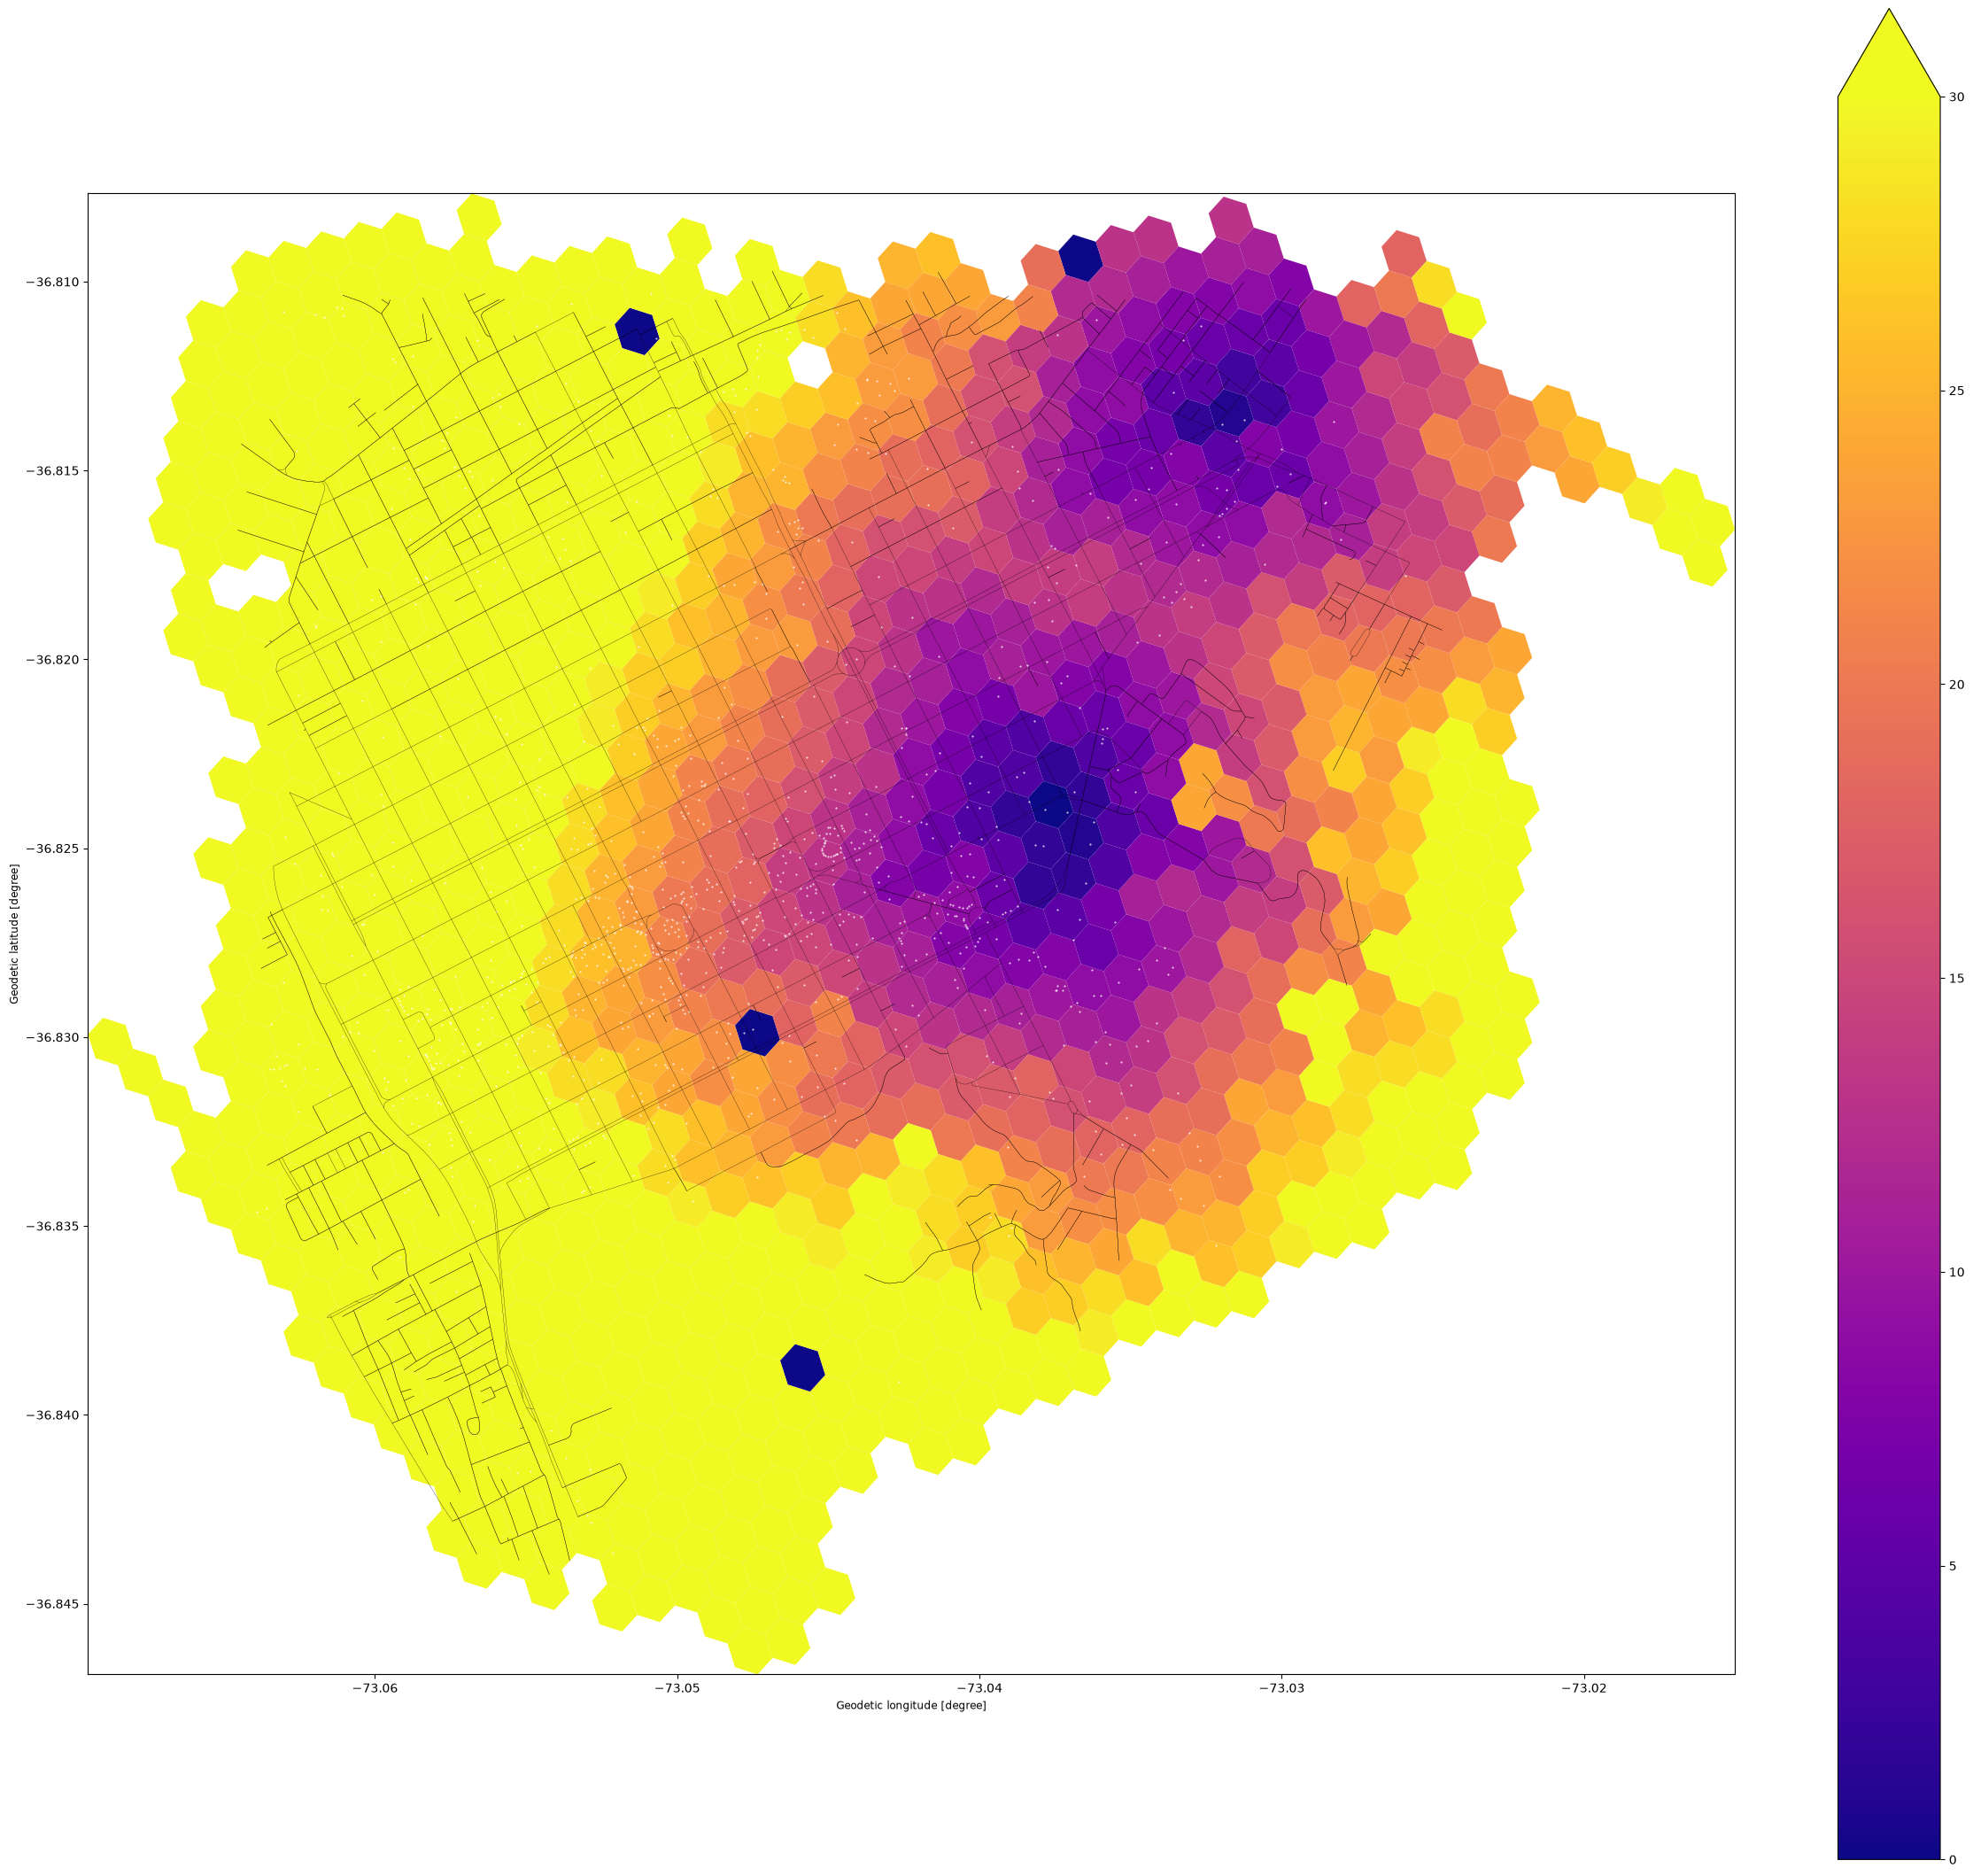

In [345]:
# modes = "walk" | "car" | "bus"
mode = "walk"
hex_matrix_gdf = hex_matrix_gdfs[mode]

ax = hex_matrix_gdf.plot(figsize=(30, 30), column="travel_time", markersize=100, cmap="plasma", vmin=0, vmax=30, legend=True)
# hex_matrix_gdf[hex_matrix_gdf.travel_time.isna()].plot(ax=ax, color="magenta")

edges.plot(ax=ax, linewidth=0.2, color="black")
destinations_gdf.plot(ax=ax, markersize=0.2, color="white")

x1, y1, x2, y2 = hex_matrix_gdf[~hex_matrix_gdf.travel_time.isna()].total_bounds
ax.set_xlim(x1, x2)
ax.set_ylim(y1, y2)

(-36.846873246818056, -36.80766703804427)

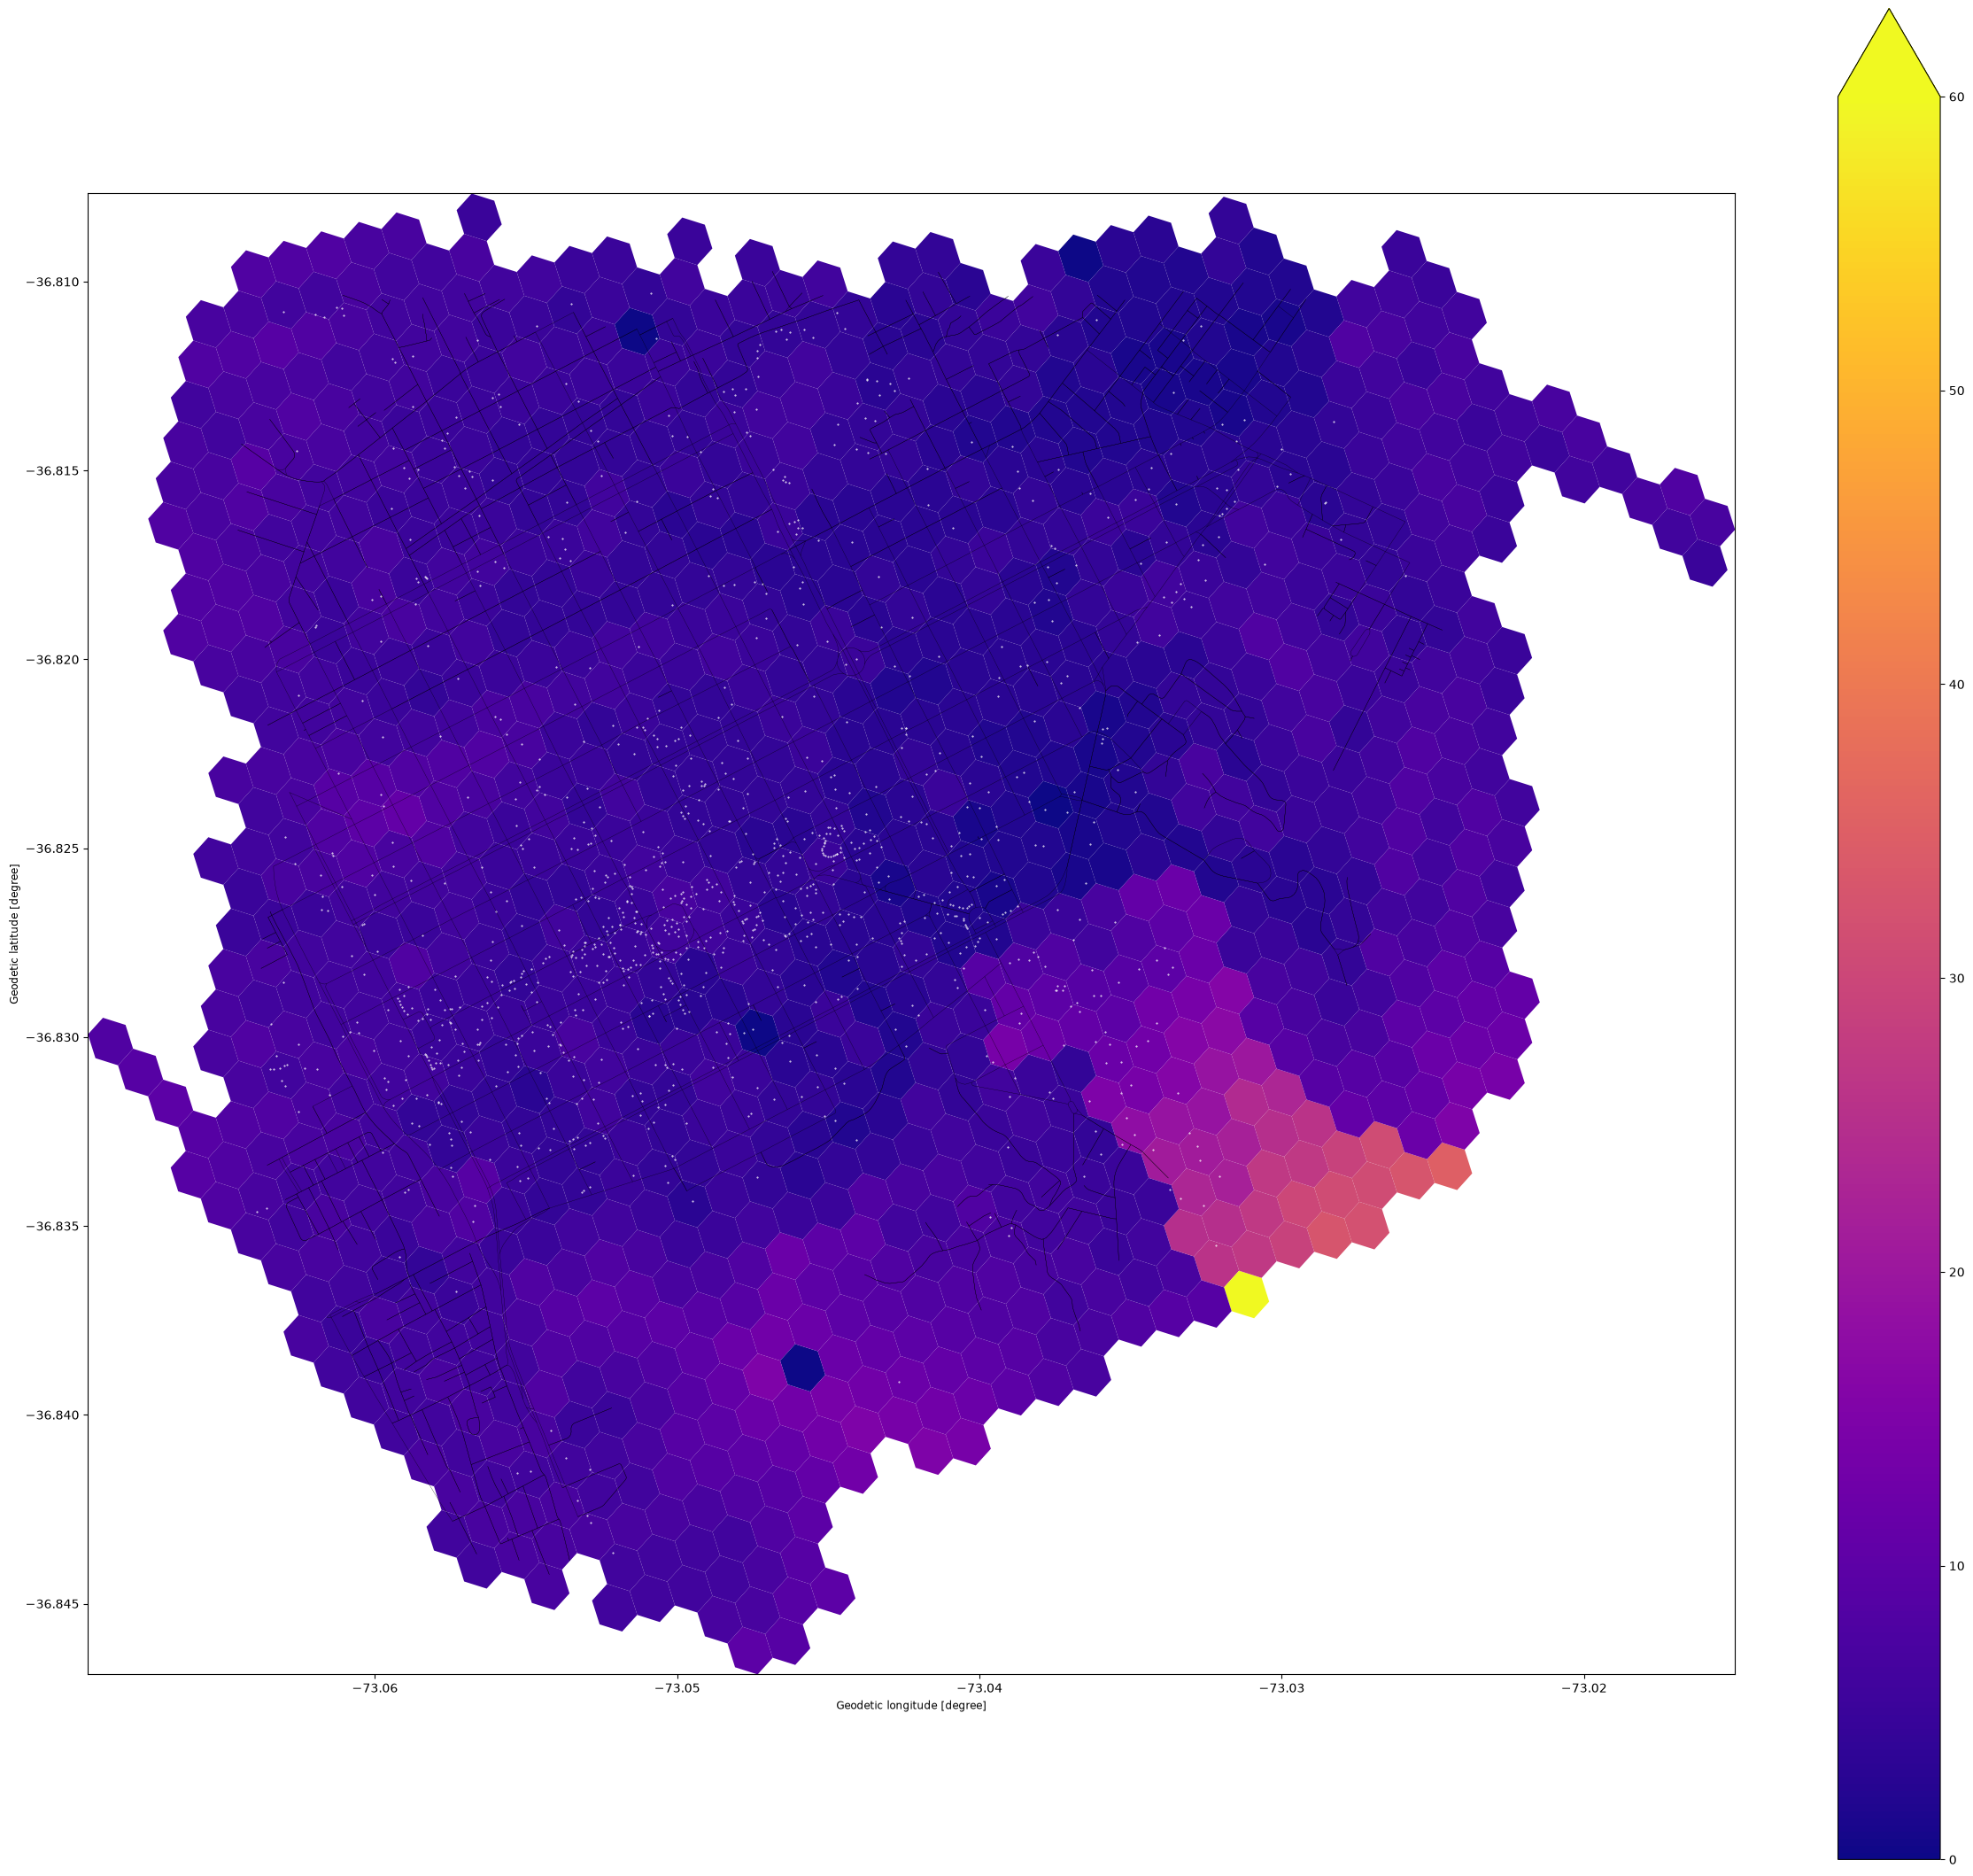

In [346]:
# modes = "walk" | "car" | "bus"
mode = "car"
hex_matrix_gdf = hex_matrix_gdfs[mode]

ax = hex_matrix_gdf.plot(figsize=(30, 30), column="travel_time", markersize=100, cmap="plasma", vmin=0, vmax=60, legend=True)
# hex_matrix_gdf[hex_matrix_gdf.travel_time.isna()].plot(ax=ax, color="magenta")

edges.plot(ax=ax, linewidth=0.2, color="black")
destinations_gdf.plot(ax=ax, markersize=0.2, color="white")

x1, y1, x2, y2 = hex_matrix_gdf[~hex_matrix_gdf.travel_time.isna()].total_bounds
ax.set_xlim(x1, x2)
ax.set_ylim(y1, y2)

(-36.846873246818056, -36.80766703804427)

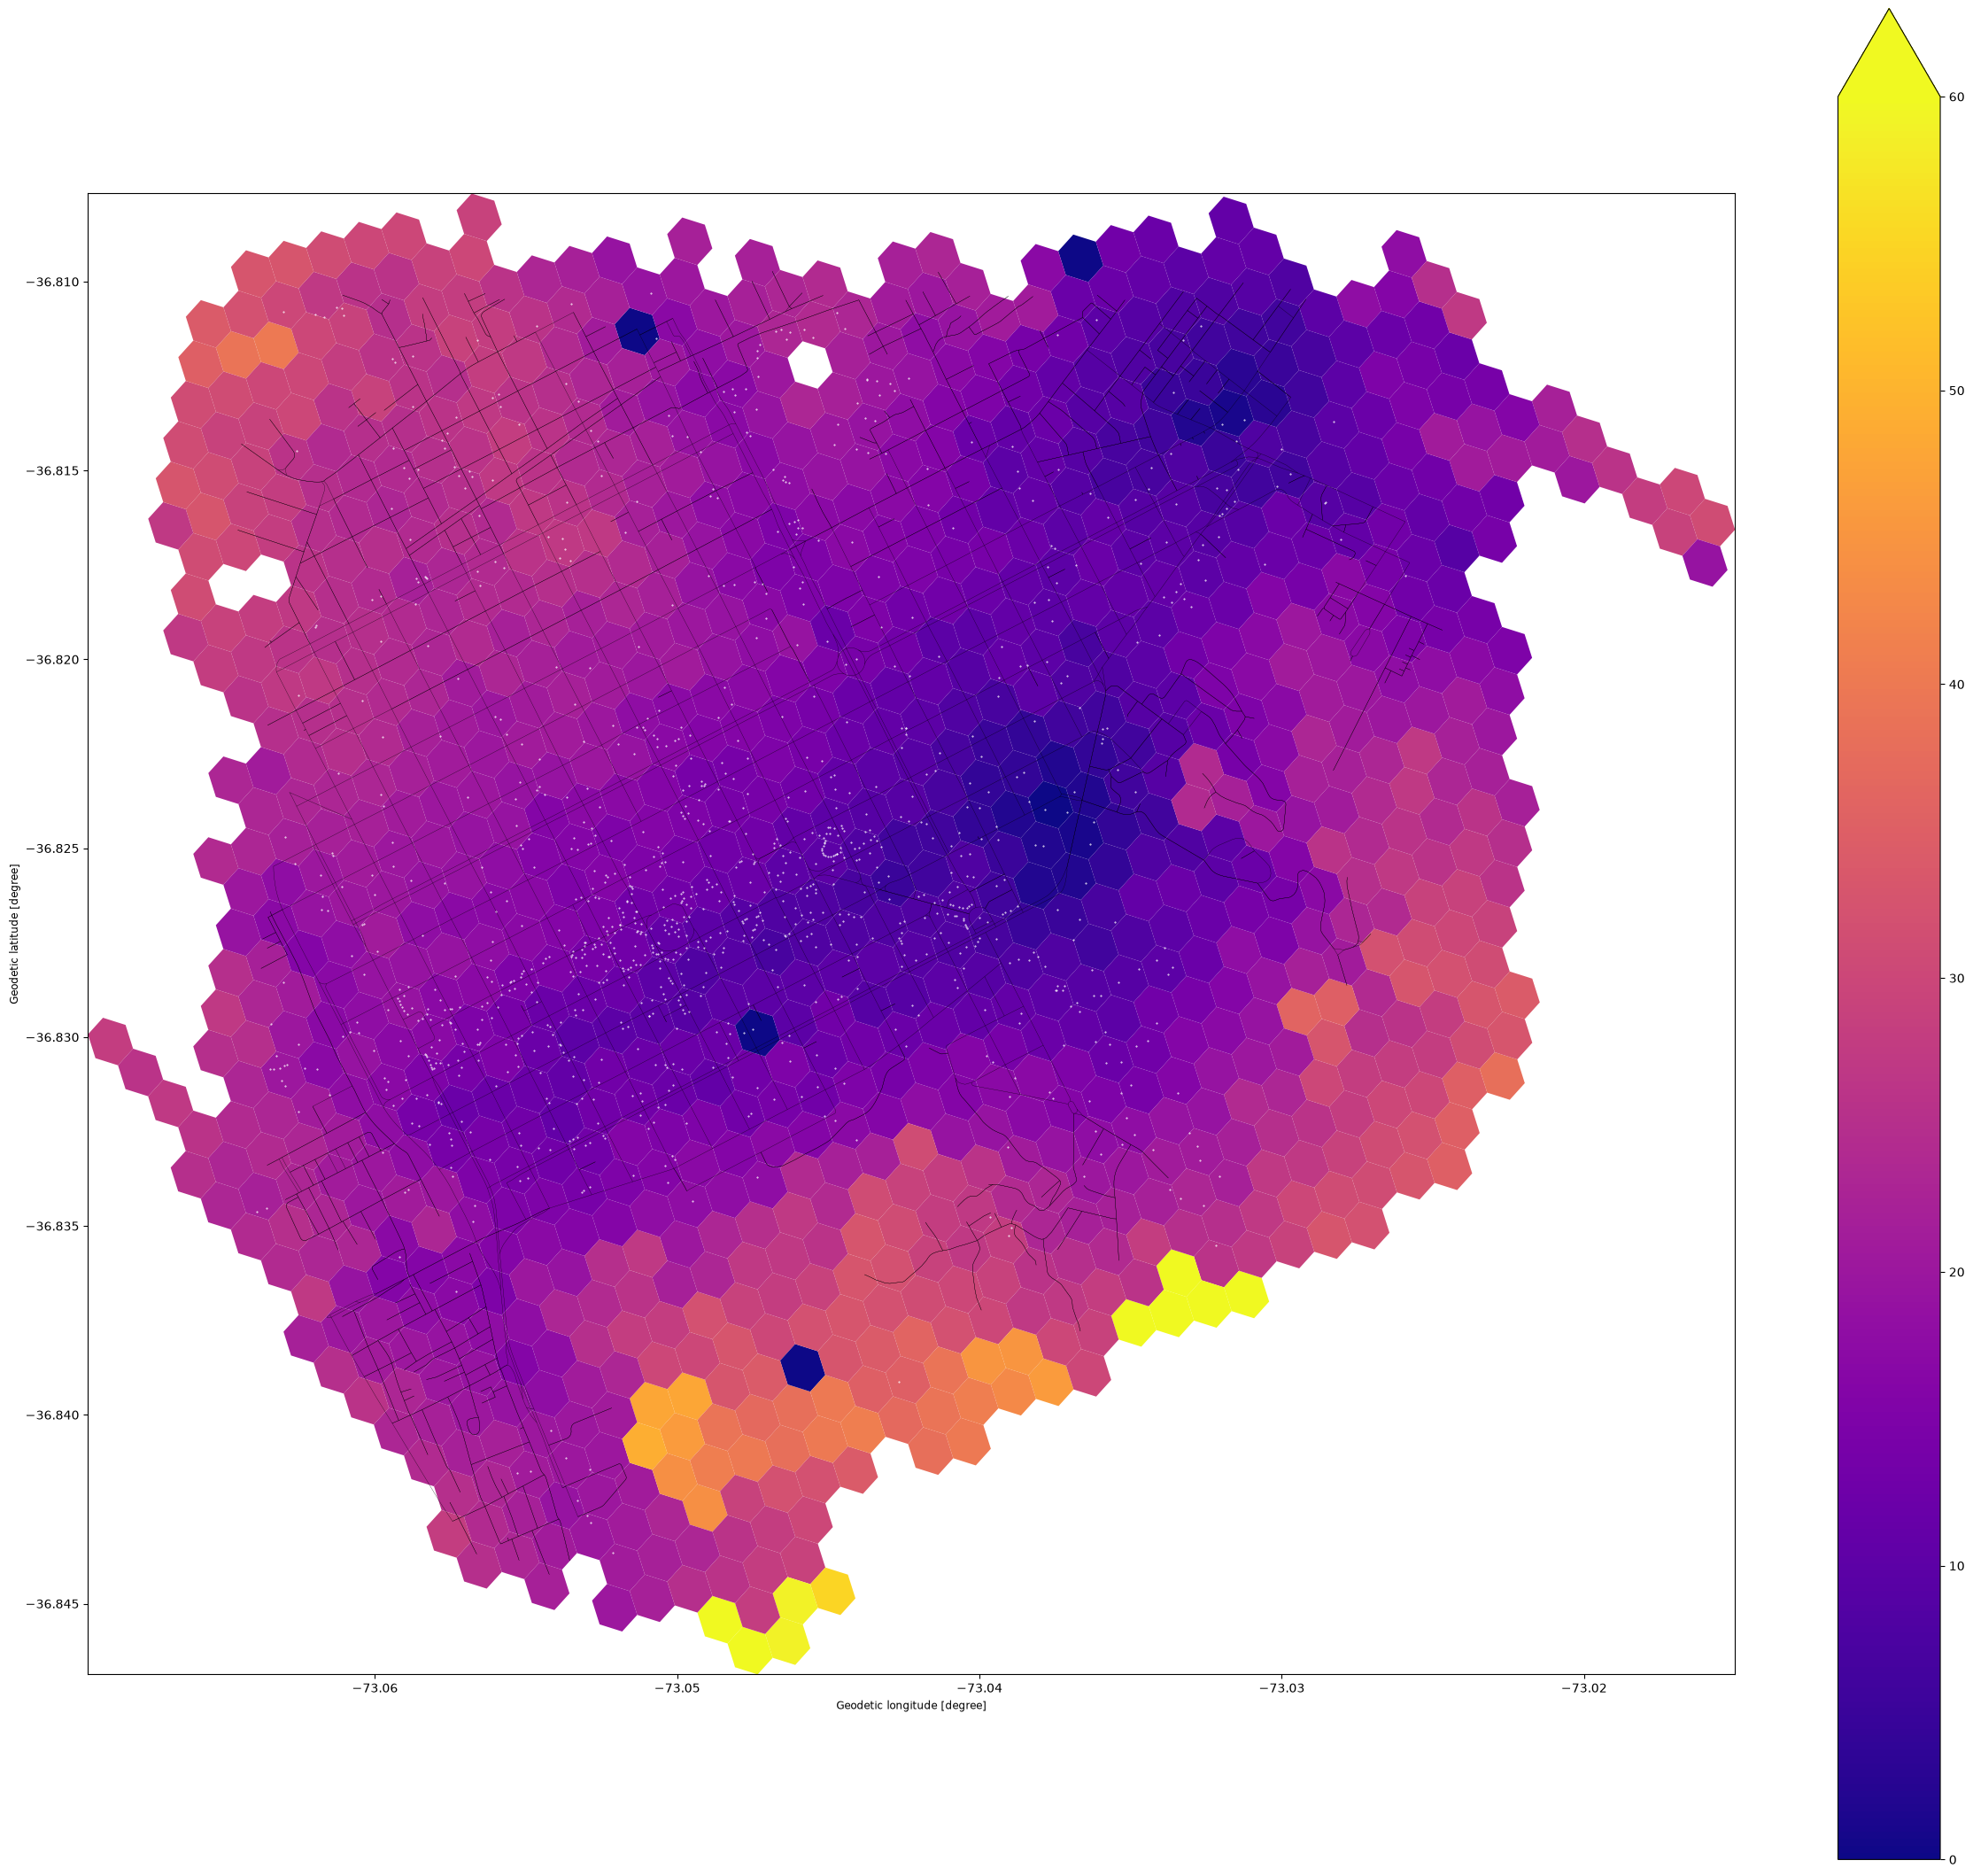

In [347]:
# modes = "walk" | "car" | "bus"
mode = "bus"
hex_matrix_gdf = hex_matrix_gdfs[mode]

ax = hex_matrix_gdf.plot(figsize=(30, 30), column="travel_time", markersize=100, cmap="plasma", vmin=0, vmax=60, legend=True)
# hex_matrix_gdf[hex_matrix_gdf.travel_time.isna()].plot(ax=ax, color="magenta")

edges.plot(ax=ax, linewidth=0.2, color="black")
destinations_gdf.plot(ax=ax, markersize=0.2, color="white")

x1, y1, x2, y2 = hex_matrix_gdf[~hex_matrix_gdf.travel_time.isna()].total_bounds
ax.set_xlim(x1, x2)
ax.set_ylim(y1, y2)

In [356]:
import pandas as pd

key = "bus"
threshold_minutes = 5
# filter_amenity = "hospital"

matrix_df = matrix_gdfs[key][["from_id", "to_id", "travel_time"]].copy()

# Filter the travel time matrix to only include pairs within your 30-minute threshold
valid_trips = matrix_df[matrix_df.travel_time <= threshold_minutes]

# merge the filtered trips with destinations
merged_df = valid_trips.merge(
    destinations_gdf, left_on="to_id", right_on="id"
)
# merged_df = merged_df[merged_df.amenity == filter_amenity]
merged_df["weight"] = 1.0

accessibility_scores = (
    merged_df.groupby("from_id")["weight"].sum().reset_index() # sum of weights by default
)

accessibility_scores.rename(
    columns={"count": "cumulative_opportunities_30min"}, inplace=True
)

print(accessibility_scores.weight.describe())
print(accessibility_scores.weight.quantile(0.95))
accessibility_scores

count    1073.000000
mean       16.069897
std        27.755626
min         1.000000
25%         1.000000
50%         6.000000
75%        16.000000
max       192.000000
Name: weight, dtype: float64
78.0


,from_id,weight
0,0,1.0
1,1,1.0
2,2,1.0
3,3,1.0
4,4,1.0
...,...,...
1068,1068,1.0
1069,1069,2.0
1070,1070,2.0
1071,1071,2.0


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

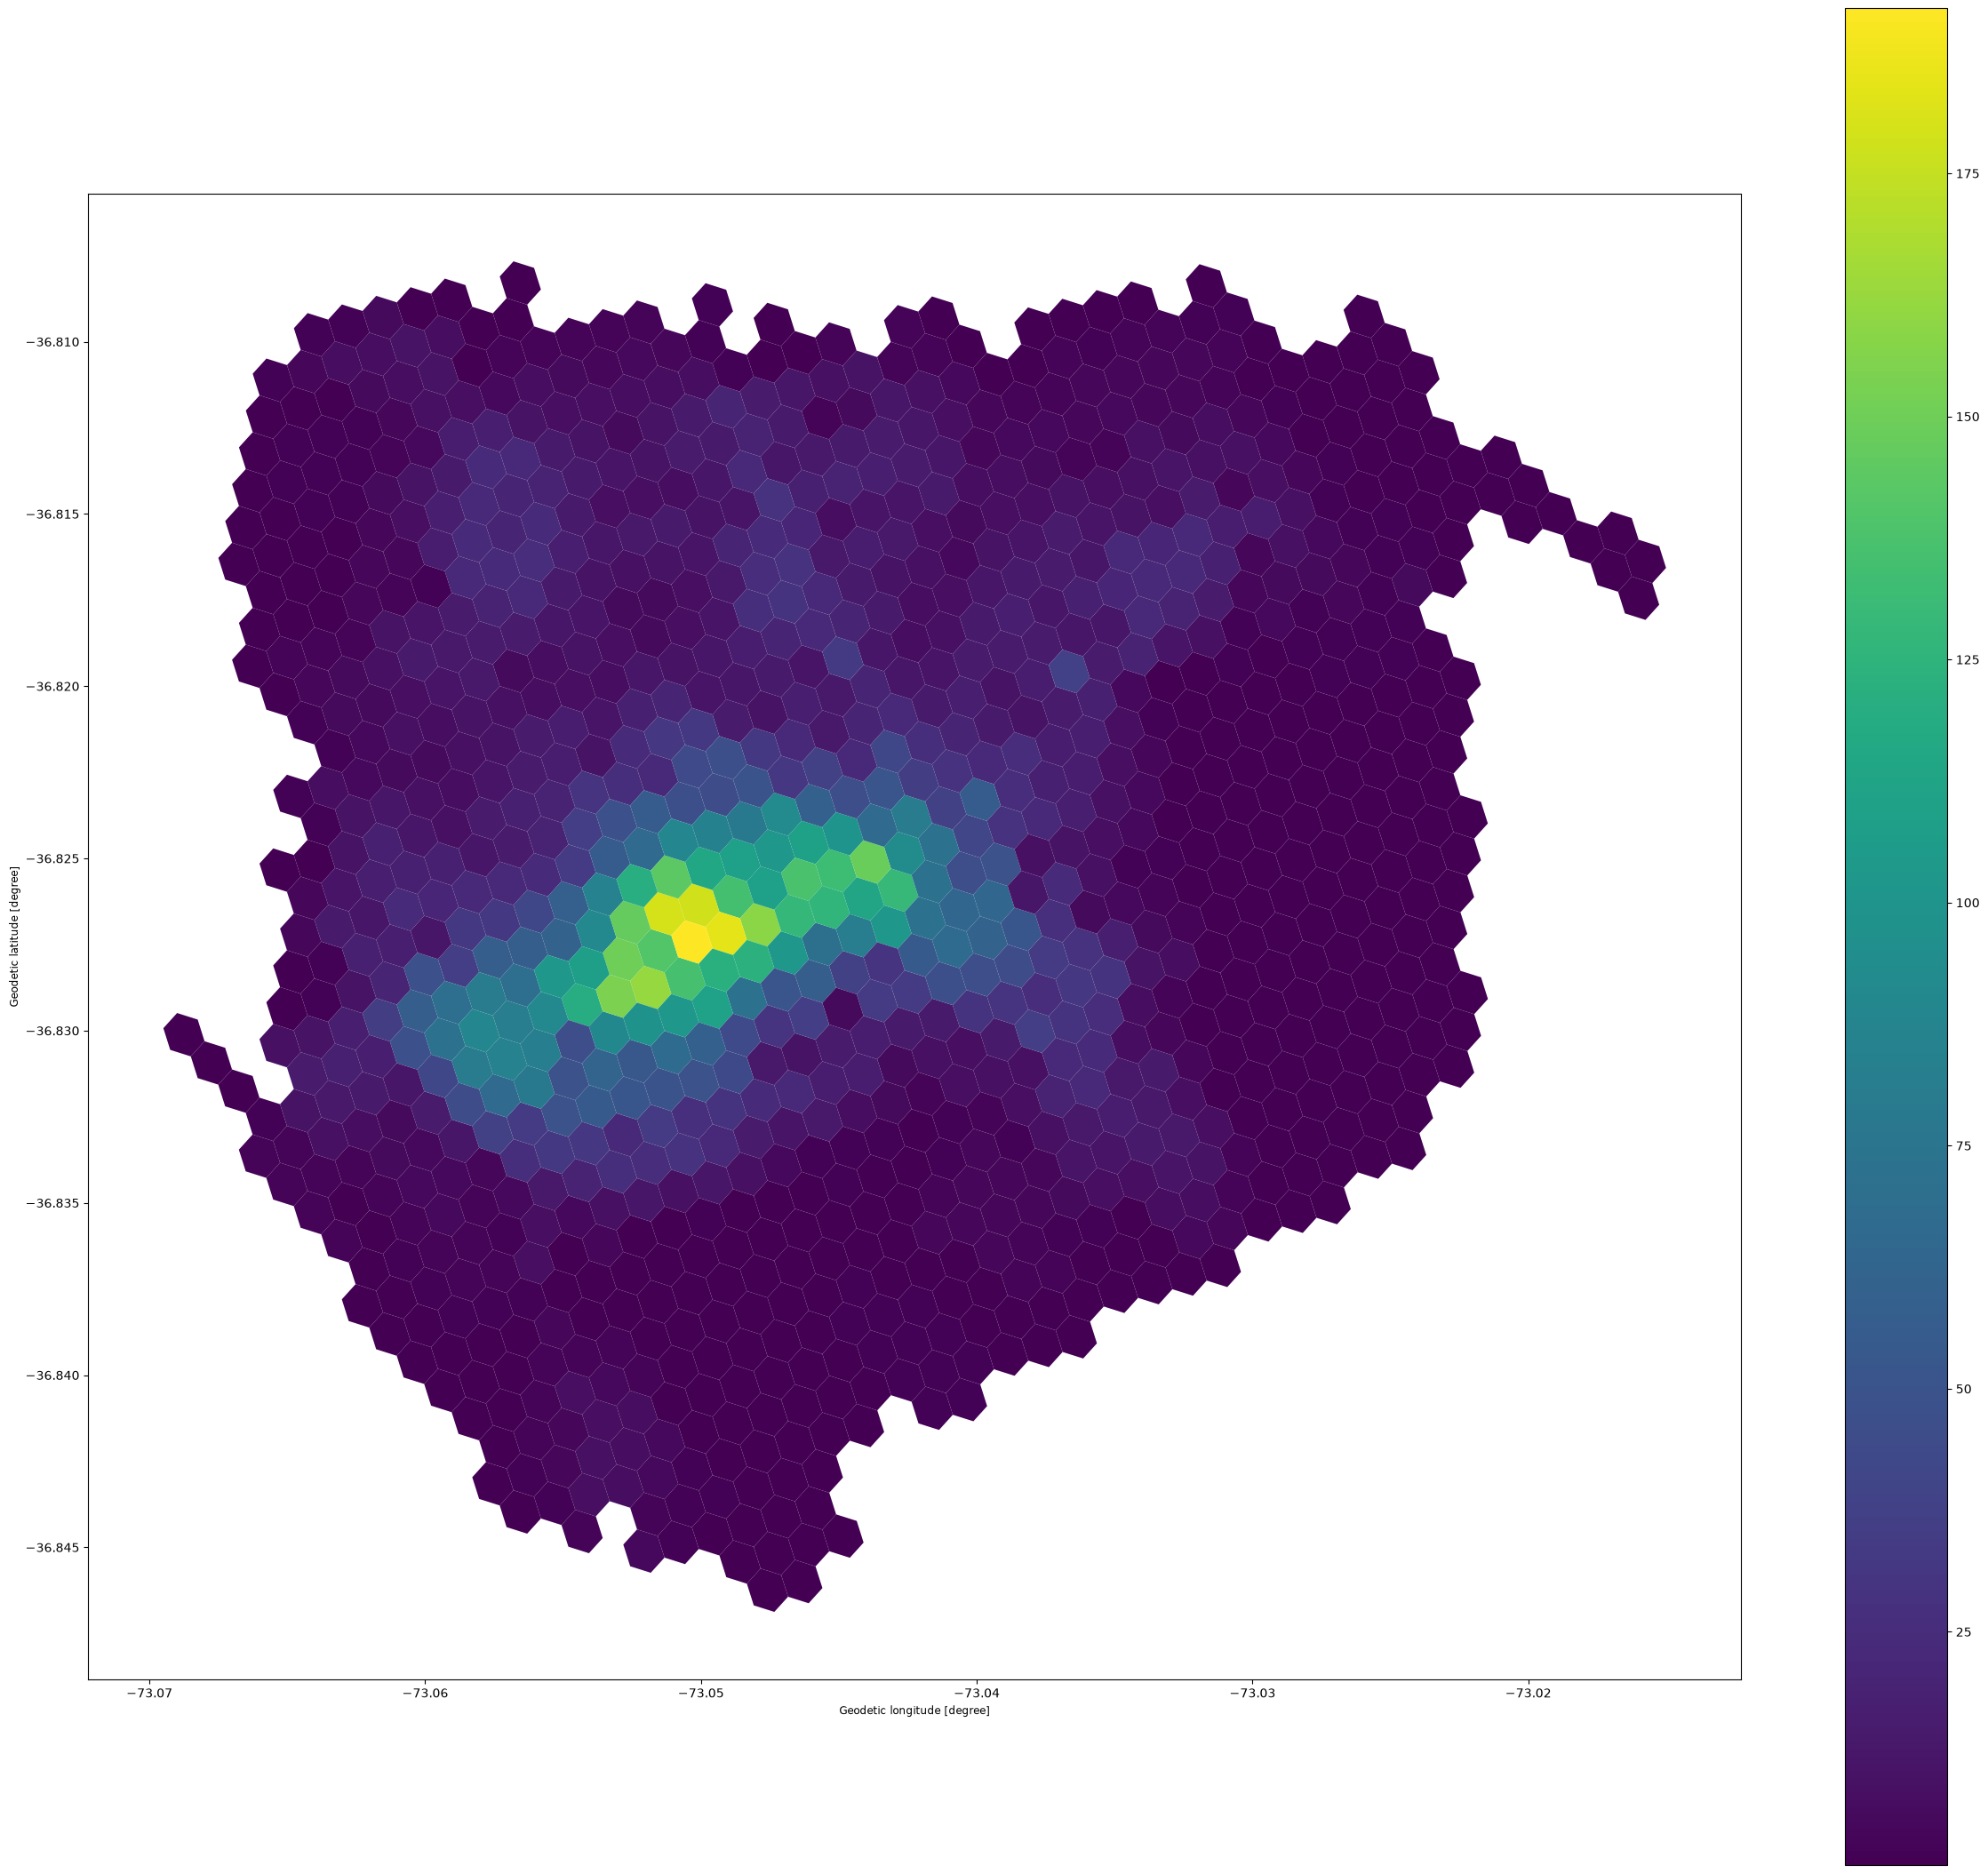

In [357]:
accessibility_hexagons = accessibility_scores.merge(hexagons_gdf, "inner", left_on="from_id", right_index=True)
accessibility_hexagons = gpd.GeoDataFrame(accessibility_hexagons, geometry="geometry", crs=4326)
# accessibility_hexagons.weight = np.log(accessibility_hexagons.weight)
# accessibility_hexagons.weight = np.sqrt(accessibility_hexagons.weight)
accessibility_hexagons.plot(figsize=(30,30), column="weight", cmap="viridis", legend=True)

In [261]:
accessibility_hexagons.weight.quantile(0.9)

np.float64(128.0)

<Axes: >

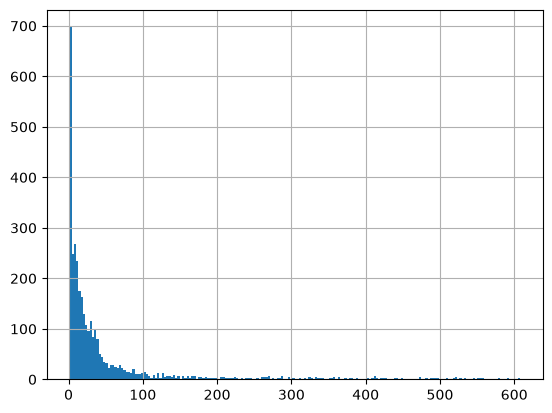

In [258]:
accessibility_hexagons.weight.hist(bins=200)

---

In [ ]:
# itinerary = r5py.DetailedItineraries(
#     transport_network=transport_network,
#     origins=origins_gdf,
#     destinations=destinations_gdf.loc[destinations_gdf.id == 2],
#     transport_modes=[r5py.TransportMode.CAR]
# )
# itineraries_gdf = itinerary.to_geodataframe()
# print(itineraries_gdf)

In [268]:
hex_travel_times = results_gdf.groupby("cell")["travel_time"].min().reset_index()
hex_travel_times

,cell,travel_time
0,89b2d868063ffff,69.0
1,89b2d86806bffff,66.0
2,89b2d86806fffff,62.0
3,89b2d86812bffff,52.0
4,89b2d868143ffff,60.0
...,...,...
498,89b2dbd3593ffff,66.0
499,89b2dbd3597ffff,71.0
500,89b2dbd359bffff,60.0
501,89b2dbd35c7ffff,63.0


In [277]:
hexagon_travel_times = matching_hexagons_gdf[["id", "cell", "geometry"]]
hexagon_travel_times = hexagon_travel_times.merge(hex_travel_times, "right", "cell")
hexagon_travel_times = hexagon_travel_times.set_geometry("geometry")
hexagon_travel_times

,id,cell,geometry,travel_time
0,NaN,89b2d868063ffff,None,69.0
1,NaN,89b2d86806bffff,None,66.0
2,NaN,89b2d86806fffff,None,62.0
3,NaN,89b2d86812bffff,None,52.0
4,NaN,89b2d868143ffff,None,60.0
...,...,...,...,...
498,NaN,89b2dbd3593ffff,None,66.0
499,NaN,89b2dbd3597ffff,None,71.0
500,NaN,89b2dbd359bffff,None,60.0
501,NaN,89b2dbd35c7ffff,None,63.0


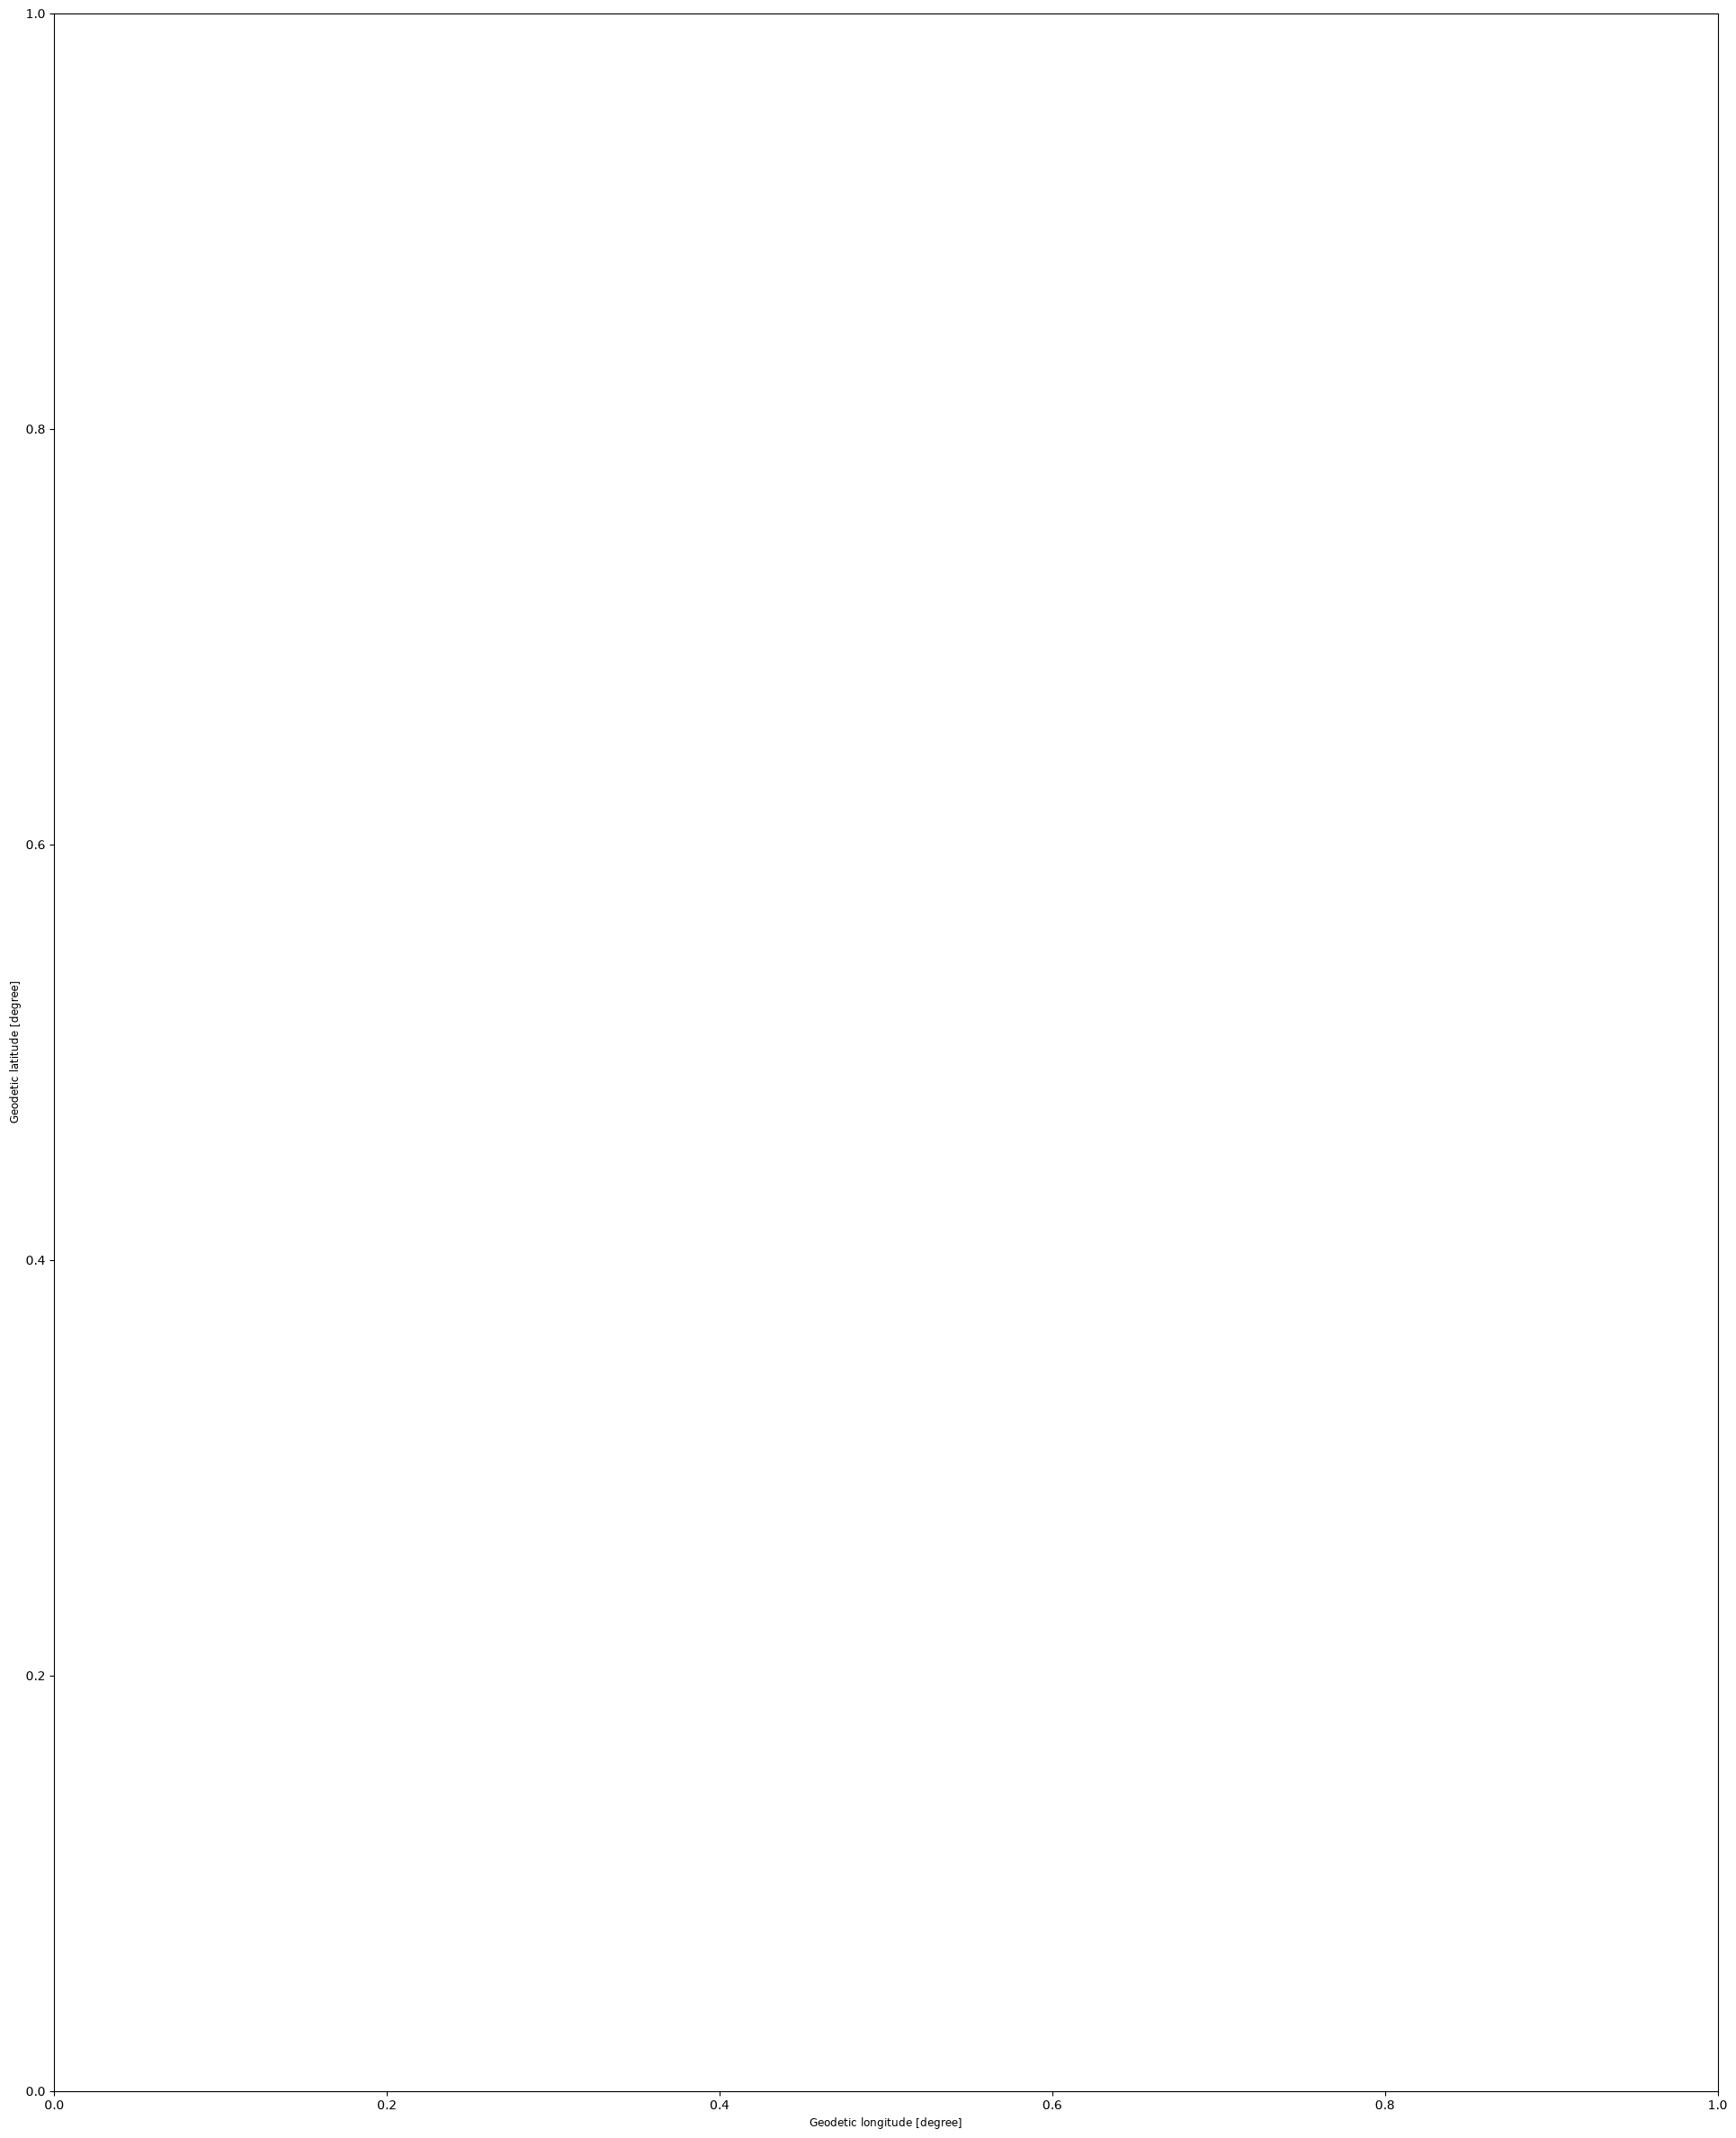

In [276]:
ax = hexagon_travel_times.plot(figsize=(30,30), column="travel_time")
# destinations_gdf.plot(ax=ax, color="red")